<center>

# 🎮 **Player Segmentation Analysis**

### Data Quality Assessment and Exploratory Data Analysis

---

**Author:** Nelson Nicolás Hernández Becerra  
**Project Type:** Product Analytics & Customer Segmentation  
**Tech Stack:** Python, Pandas, Scikit-Learn, Matplotlib, Seaborn

</center>

# 📖 **Notebook Overview**

After completing the initial dataset diagnosis, the next step is to evaluate data quality and perform an exploratory analysis of the available variables.

This notebook focuses on understanding the quality, distribution, and relationships of the data before any feature engineering or clustering techniques are applied.

The insights generated in this stage will help identify potential issues, uncover behavioral patterns, and provide a stronger foundation for the player segmentation process.

# <font color='green'>**Dataset Loading**</font>

Before starting the data quality assessment, we load the dataset and initialize the environment required for the analysis.

This ensures that all subsequent steps are reproducible and independent from previous notebooks.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

pd.set_option("display.max_columns", None)

DATASET_PATH = Path("../data/raw/dataset.csv")

df = pd.read_csv(DATASET_PATH)

print("✅ Dataset loaded successfully.")

✅ Dataset loaded successfully.


# <font color='green'>📊 **Step 2. Data Quality Assessment**</font>

In this stage, we evaluate the overall quality of the dataset and identify potential issues that may affect subsequent analysis.

The objective is to confirm that the data is suitable for exploration and modeling while documenting any limitations, inconsistencies, or preprocessing requirements identified during the review process.

## <font color='green'>🟢 **2.1 Missing Values Analysis**</font>

In this section, we perform a detailed assessment of missing values across the dataset.

Understanding the distribution of missing data is essential for determining whether these values represent data quality issues, valid business situations, or information that requires preprocessing before analysis.

In [2]:
missing_values = (
    df.isnull()
      .sum()
      .to_frame("missing_count")
      .assign(
          missing_percentage=lambda x: (
              x["missing_count"] / len(df) * 100
          )
      )
      .sort_values(
          by="missing_percentage",
          ascending=False
      )
)

missing_values

,missing_count,missing_percentage
Purchase Date,788,39.4
Purchase Amount,756,37.8
Purchase Type,756,37.8
Attempts,0,0.0
Level,0,0.0
Player ID,0,0.0
Time Played,0,0.0
Level Completion Time,0,0.0
Avg Daily Login,0,0.0
Lives from Ads,0,0.0


Missing values are limited to purchase-related variables:

- `Purchase Date` (39.4%)
- `Purchase Amount` (37.8%)
- `Purchase Type` (37.8%)

All remaining variables contain complete information, indicating a high overall level of data completeness.

The concentration of missing values within monetization features suggests that these records may correspond to players who have not made in-app purchases rather than representing a data quality issue.

This interpretation will be investigated further before applying any imputation strategy or removing observations.

### <font color='green'> **2.1.1 Relationship Between Purchase-Related Missing Values** </font>

In this section, we investigate whether missing values in purchase-related variables occur simultaneously.

This analysis helps determine whether the missing data represents a consistent business scenario, such as players who have not made purchases, rather than independent data quality issues.

In [3]:
df[
    ["Purchase Amount", "Purchase Date", "Purchase Type"]
].isnull().sum()

Purchase Amount    756
Purchase Date      788
Purchase Type      756
dtype: int64

The missing value counts for `Purchase Amount` and `Purchase Type` are identical, suggesting a strong relationship between these variables.

However, `Purchase Date` contains an additional 32 missing values compared to the other purchase-related features.

This discrepancy indicates that purchase-related missing values may not follow a perfectly consistent pattern across all records. A deeper investigation is therefore required before determining whether these missing values represent valid business scenarios or data quality issues.


### <font color='green'>**2.1.2 Consistency Check of Purchase-Related Variables**</font>

In this section, we assess the consistency of purchase-related variables.

Since the number of missing values differs slightly across purchase features, it is important to verify whether all missing records correspond to non-paying players or whether inconsistencies exist within the monetization data.

In [4]:
df[
    (df["Purchase Amount"].isna()) &
    (df["Purchase Date"].notna())
]

,Player ID,Level,Attempts,Time Played,Booster Used,Avg Daily Login,Level Completion Time,Specific Action Usage,Lives from Ads,Purchase Amount,Purchase Date,Purchase Type,Device Type,OS Version,Friend Invites Sent,Friend Invites Received,Guild Chat Messages,Facebook Connect Status,Social Engagement through Facebook
209,156671,114,23,800,2,24,381,Color Bomb Creation,3,NaN,2023-12-12,NaN,iPad,15.6,4,0,10,No,low
217,229462,126,400,800,58,1,561,Extra Time Boost,2,NaN,2023-12-12,NaN,iPad,14.0,32,18,19,Yes,low
309,350942,10,4,7002,7,11,1347,Striped Candy Blast,0,NaN,2023-11-28,NaN,iPad,14.5,18,12,35,Yes,low
531,213450,10,4,19428,15,5,50,Fish Blast,0,NaN,2023-11-08,NaN,iPad,13.8,76,4,8,No,low
543,302535,51,34,9693,3,11,827,Wrapped Candy Swap,5,NaN,2023-11-08,NaN,Samsung Galaxy,13.7,29,0,23,Yes,low
968,776774,180,4,5408,95,6,50,Wrapped Candy Blast,4,NaN,2023-09-19,NaN,Android,15.4,7,0,40,No,low
1044,4909,10,4,17323,5,24,877,Special Candy Swap,2,NaN,2023-09-08,NaN,Android,11.2,7,7,33,No,low
1056,77667,10,50,800,95,24,1337,Extra Moves,5,NaN,2023-09-08,NaN,iPhone,11.2,33,51,34,No,low
1057,82823,429,49,800,95,1,2265,Fish Blast,31,NaN,2023-09-08,NaN,iPhone,15.7,19,1,101,No,low
1175,985720,10,211,800,10,1,2280,Fish Usage,0,NaN,2023-09-04,NaN,Android,12.3,27,0,0,Yes,low


The analysis identified records where `Purchase Date` is available while both `Purchase Amount` and `Purchase Type` are missing.

This pattern suggests the presence of inconsistencies within the purchase-related data, as a purchase date would typically be accompanied by information about the transaction itself.

Although the number of affected records appears to be relatively small, these cases should be documented and considered during the preprocessing stage.

### <font color='green'>**2.1.3 Quantifying Purchase Data Inconsistencies**</font>

In this section, we quantify the number of records where a purchase date exists but the corresponding purchase information is missing.

This assessment helps measure the scope of the inconsistency and determine whether it is likely to have a significant impact on the analysis.

In [5]:
purchase_inconsistencies = df[
    (df["Purchase Amount"].isna()) &
    (df["Purchase Date"].notna())
]

purchase_inconsistencies.shape[0]

10

A total of **10 records** contain a valid `Purchase Date` while both `Purchase Amount` and `Purchase Type` are missing.

Although this represents a relatively small portion of the dataset, it indicates that some inconsistencies exist within the purchase-related information.

These records should be documented and reviewed during the preprocessing stage before any monetization-related analysis is conducted.

### <font color='green'>**2.1.4 Reverse Consistency Check**</font>

In this section, we investigate whether purchase information exists without an associated purchase date.

This verification helps identify additional inconsistencies within the monetization-related variables and provides a more complete understanding of the missing data patterns.

In [6]:
df[
    (df["Purchase Amount"].notna()) &
    (df["Purchase Date"].isna())
]

,Player ID,Level,Attempts,Time Played,Booster Used,Avg Daily Login,Level Completion Time,Specific Action Usage,Lives from Ads,Purchase Amount,Purchase Date,Purchase Type,Device Type,OS Version,Friend Invites Sent,Friend Invites Received,Guild Chat Messages,Facebook Connect Status,Social Engagement through Facebook
1231,139455,23,109,31896,30,5,91,Fish Usage,7,23.29,NaN,In-App,iPad,17.9,26,83,1,No,moderate
1232,139657,32,4,800,95,1,50,Extra Moves,3,5.27,NaN,In-App,iPad,11.2,0,2,49,No,low
1242,8139,52,4,800,11,1,433,Color Bomb Creation,3,1.68,NaN,In-App,iPad,11.2,19,26,37,No,low
1243,8143,70,8,800,1,6,50,Special Candy Swap,49,12.23,NaN,In-App,iPhone,19.2,76,0,31,Yes,low
1246,8346,34,324,32105,4,10,216,Extra Time Boost,0,18.12,NaN,In-App,iPhone,11.2,13,9,0,No,moderate
1247,8538,107,4,2843,7,24,639,Wrapped Candy Blast,8,12.36,NaN,In-App,iPad,13.8,54,0,65,No,low
1382,139204,11,73,12271,0,2,50,Striped Candy Swipe,5,5.51,NaN,In-App,iPad,14.3,18,8,6,No,low
1443,28869,70,38,45167,0,24,50,Color Bomb Creation,8,6.17,NaN,In-App,iPad,14.8,58,19,20,No,high
1444,28869,10,334,5263,14,10,510,Fish Usage,31,3.22,NaN,In-App,iPad,14.9,19,23,0,No,low
1445,28869,10,75,800,6,9,600,Special Candy Swap,27,5.00,NaN,In-App,iPhone,14.4,1,0,0,Yes,low


The reverse consistency check identified records containing valid purchase information (`Purchase Amount` and `Purchase Type`) but missing values in `Purchase Date`.

Combined with the previous analysis, these findings confirm that purchase-related variables do not follow a perfectly consistent missing-value pattern.

Although the inconsistencies affect a relatively small subset of records, they should be documented and carefully considered during data preprocessing, particularly for any analyses involving purchase history or temporal behavior.

At this stage, the missing values appear to be a combination of valid business scenarios (non-paying players) and a small number of data consistency issues within the monetization features.

### <font color='green'>**2.1.5 Purchase Data Overview**</font>

The previous checks examined each inconsistency separately. To obtain a complete picture, we cross-tabulate the presence of `Purchase Amount` and `Purchase Date`, which covers all four possible combinations and allows us to verify that every record is accounted for.

In [7]:
purchase_pattern = pd.crosstab(
    df["Purchase Amount"].notna().rename("has_amount"),
    df["Purchase Date"].notna().rename("has_date"),
    margins=True
)

purchase_pattern

has_date,False,True,All
has_amount,,,
False,746,10,756
True,42,1202,1244
All,788,1212,2000


The cross-tabulation accounts for all 2,000 records and shows that purchase information is consistent in most of them:

- **1,202 records (60.1%)** have both `Purchase Amount` and `Purchase Date`.
- **746 records (37.3%)** have neither, which corresponds to players without purchases.
- **42 records (2.1%)** have a purchase amount but no date.
- **10 records (0.5%)** have a purchase date but no amount.

In total, **52 records (2.6%)** show inconsistent purchase information, while 97.4% follow a coherent pattern. This also explains the 32 additional missing dates noted earlier: they are the net result of 42 records with a missing date minus 10 records with a date but no amount.

### <font color='green'>**2.1.6 Purchase Inconsistencies Decision**</font>

The two types of inconsistency are treated differently:

- **Records with an amount but no date (42):** `Purchase Amount` is present and valid, and `Purchase Date` is not used in the segmentation. These records are retained without changes and classified as payers.
- **Records with a date but no amount (10):** the amount is unknown. Imputing a value would invent information, and removing 10 records is not justified. They are retained with `Purchase Amount` set to zero, which classifies them as non-payers, consistent with the treatment applied to all missing amounts.

**Limitation:** some of these 10 records may correspond to real purchases whose amount was not recorded. Since they represent 0.5% of the dataset, reclassifying them would change the share of payers from 62.2% to 62.7%, an effect that is considered negligible for the segmentation.

## <font color='green'>🟢 **2.2 Data Type Assessment**</font>

In this section, we review the current data types of the dataset and identify variables that may require conversion before exploratory analysis and modeling.

Ensuring that each feature is stored using an appropriate data type helps improve data quality, facilitates analysis, and supports more efficient preprocessing workflows.

In [8]:
df.dtypes

Player ID                               int64
Level                                   int64
Attempts                                int64
Time Played                             int64
Booster Used                            int64
Avg Daily Login                         int64
Level Completion Time                   int64
Specific Action Usage                     str
Lives from Ads                          int64
Purchase Amount                       float64
Purchase Date                             str
Purchase Type                             str
Device Type                               str
OS Version                            float64
Friend Invites Sent                     int64
Friend Invites Received                 int64
Guild Chat Messages                     int64
Facebook Connect Status                   str
Social Engagement through Facebook        str
dtype: object

Most variables are stored using appropriate numerical data types (`int64` and `float64`), which facilitates quantitative analysis and statistical exploration.

Several features are currently represented as text-based variables, including player actions, device information, purchase attributes, and social engagement indicators.

A notable observation is that `Purchase Date` is stored as a string rather than a datetime object. Converting this variable to a datetime format may be necessary if temporal analyses are performed later in the project.

At this stage, no critical data type issues have been identified, although some transformations may improve the analytical usability of certain variables.

### <font color='green'>**2.2.1 Variable Classification by Data Type**</font>

In this section, we classify the available variables according to their current data types.

This review provides a clearer understanding of the dataset structure and helps determine which variables may require specific preprocessing techniques during later stages of the project.

In [9]:
df.select_dtypes(include=["number"]).columns.tolist()

['Player ID',
 'Level',
 'Attempts',
 'Time Played',
 'Booster Used',
 'Avg Daily Login',
 'Level Completion Time',
 'Lives from Ads',
 'Purchase Amount',
 'OS Version',
 'Friend Invites Sent',
 'Friend Invites Received',
 'Guild Chat Messages']

The dataset contains a substantial number of numerical variables representing player progression, engagement, monetization, social activity, and device-related information.

These features are likely to play a central role in the exploratory analysis and future segmentation process, as they capture measurable aspects of player behavior.

It is also important to note that `Player ID` is stored as a numerical variable, although it functions as an identifier rather than a quantitative feature. Its reliability as a player-level key is assessed in section 2.3, and it is excluded from the analysis and modeling stages.

### <font color='green'>**2.2.2 Categorical Variables**</font>

In this section, we identify the variables currently stored as text-based features.

Understanding the available categorical information is important because these variables may require encoding techniques before being used in machine learning models.

In [10]:
df.select_dtypes(include=["object", "string"]).columns.tolist()

['Specific Action Usage',
 'Purchase Date',
 'Purchase Type',
 'Device Type',
 'Facebook Connect Status',
 'Social Engagement through Facebook']

The dataset contains a relatively small set of categorical variables covering player actions, purchase information, device usage, and social engagement.

Most of these features are likely to provide valuable behavioral context and may contribute to the segmentation process after appropriate preprocessing.

Among these variables, `Purchase Date` stands out as a candidate for data type conversion, while the remaining features could require encoding techniques before being used in machine learning algorithms.

## <font color='green'>🟢 **2.3 Record Granularity Assessment**</font>

The initial diagnosis showed that the dataset contains 2,000 records but only 1,386 unique `Player ID` values. Before engineering features or building segments, it is necessary to understand what each row represents: a unique player, or an observation that can be repeated for the same identifier.

This section quantifies how records are distributed across identifiers and evaluates whether `Player ID` can be used as a reliable player-level key.

### <font color='green'>**2.3.1 Records per Player ID**</font>

We count how many records each identifier has and summarize how many identifiers fall into each group. This shows whether the repetition is marginal or widespread.

In [11]:
records_per_id = df["Player ID"].value_counts()

distribution = (
    records_per_id
    .value_counts()
    .sort_index()
    .rename_axis("records_per_id")
    .to_frame("number_of_ids")
)

distribution["share_of_ids_%"] = (
    distribution["number_of_ids"] / distribution["number_of_ids"].sum() * 100
).round(1)

distribution

,number_of_ids,share_of_ids_%
records_per_id,,
1,972,70.1
2,336,24.2
3,34,2.5
4,30,2.2
5,1,0.1
6,3,0.2
7,1,0.1
8,3,0.2
9,2,0.1


The distribution shows that repetition is widespread rather than marginal:

- **972 identifiers (70.1%)** appear in a single record.
- **414 identifiers (29.9%)** appear more than once, and together they account for **1,028 records, 51.4% of the dataset**.
- Most repeated identifiers have exactly 2 records (336 identifiers), but a few reach 12, 15, and even 23 records.

Since more than half of the rows belong to repeated identifiers, the way these records are interpreted directly affects the analysis. The next step is to evaluate whether repeated records describe the same player or different ones.

### <font color='green'>**2.3.2 Attribute Consistency within Repeated IDs**</font>

If a repeated `Player ID` represented the same player, attributes that are expected to remain stable (such as device type, operating system version, and Facebook connection status) should have the same value across all of its records.

For each identifier with more than one record, we check whether these attributes keep a single value, and report the percentage of identifiers where that holds.

In [12]:
repeated = df[df["Player ID"].duplicated(keep=False)]

stable_attributes = ["Device Type", "OS Version", "Facebook Connect Status"]

consistency = (
    repeated
    .groupby("Player ID")[stable_attributes]
    .nunique()
    .eq(1)
    .mean()
    .mul(100)
    .round(1)
    .to_frame("ids_with_constant_value_%")
)

consistency

,ids_with_constant_value_%
Device Type,30.2
OS Version,3.4
Facebook Connect Status,48.8


The consistency check shows that repeated identifiers do not behave like a single player. Among identifiers with more than one record:

- `Device Type` keeps a single value in only **30.2%** of identifiers.
- `OS Version` keeps a single value in only **3.4%** of identifiers.
- `Facebook Connect Status` keeps a single value in **48.8%** of identifiers.

Attributes that should remain stable for the same player change in most cases, which suggests that `Player ID` does not tie records to a single device, operating system, or account state. Consequently, `Player ID` cannot be treated as a reliable player-level key.

### <font color='green'>**2.3.3 Unit of Analysis Decision**</font>

Based on the evidence gathered in this section:

- A repeated `Player ID` does not identify a consistent player, since attributes that should be stable change in most repeated identifiers.
- Aggregating records by `Player ID` would merge observations with different devices and behavioral profiles, producing averages that do not describe any real observation.
- Keeping a single record per identifier would discard 614 records without a defensible selection criterion.

For these reasons, **each of the 2,000 rows is treated as an independent player record**, and `Player ID` is excluded both as a grouping key and as a modeling feature.

**Limitation:** the resulting segments describe behavioral profiles of records rather than unique individuals. If some identifiers did correspond to the same person, that person could appear in more than one segment, and the dataset offers no reliable way to verify this.

**Terminology:** from this point on, counts and chart labels refer to *records*. In the narrative, the word "players" is used as shorthand for player records.

## <font color='green'>🟢 **2.4 Boundary Values Assessment**</font>

The initial diagnosis showed that, for several numerical variables, the minimum value coincides with the 25th percentile. This suggests that a substantial share of records may sit exactly at the lower bound of the variable, which can happen with default values, censoring, or system limits.

Since such values can distort distributions and the distance calculations used in clustering, we quantify how many records are located at the minimum and at the maximum of each numerical variable.

### <font color='green'>**2.4.1 Records at the Minimum and Maximum**</font>

For each numerical variable, we report its minimum and maximum, and the percentage of records that take exactly those values. `Player ID` is excluded because it is an identifier, and `Purchase Amount` is excluded because its missing values were already analyzed in section 2.1.

In [13]:
numeric_cols = df.select_dtypes(include="number").columns.drop(
    ["Player ID", "Purchase Amount"]
)

boundary_check = pd.DataFrame({
    "min": df[numeric_cols].min(),
    "rows_at_min_%": (df[numeric_cols] == df[numeric_cols].min()).mean() * 100,
    "max": df[numeric_cols].max(),
    "rows_at_max_%": (df[numeric_cols] == df[numeric_cols].max()).mean() * 100
}).round(1)

boundary_check.sort_values("rows_at_min_%", ascending=False)

,min,rows_at_min_%,max,rows_at_max_%
Time Played,800.0,45.0,95000.0,2.4
Lives from Ads,0.0,34.6,49.0,4.0
Level,10.0,34.2,998.0,1.6
Level Completion Time,50.0,27.5,2280.0,2.1
Attempts,4.0,25.2,400.0,5.9
Avg Daily Login,1.0,24.2,24.0,17.9
Guild Chat Messages,0.0,21.4,162.0,1.1
Friend Invites Received,0.0,20.4,112.0,3.4
Friend Invites Sent,0.0,17.2,76.0,2.4
OS Version,11.2,15.7,19.3,3.8


The results reveal two different situations.

**Natural zeros.** `Lives from Ads`, `Guild Chat Messages`, `Friend Invites Received`, `Friend Invites Sent`, and `Booster Used` have a minimum of 0 shared by 14% to 35% of records. For count variables, zero simply means no activity, so these values are plausible and are not considered suspicious.

**Possible floor effects.** Five variables have a **non-zero** minimum shared by a large share of records:

- `Time Played`: **45.0%** of records at 800
- `Level`: **34.2%** at 10
- `Level Completion Time`: **27.5%** at 50
- `Attempts`: **25.2%** at 4
- `Avg Daily Login`: **24.2%** at 1

A non-zero minimum held by a quarter to almost half of the records is unlikely to occur naturally, and may reflect default values, censoring, or system limits. In addition, `Avg Daily Login` shows a possible ceiling, with **17.9%** of records at its maximum of 24.

`OS Version` (15.7% at its lowest version) is a version label rather than a behavioral measure, so it is not considered here.

The dataset does not allow us to verify the origin of these values. The next step evaluates whether the floor values occur in the same records, which would indicate a structured pattern rather than independent coincidences.

### <font color='green'>**2.4.2 Co-occurrence of Floor Values**</font>

For each record, we count in how many of the five floor-affected variables it sits exactly at the minimum. We compare the observed distribution with the distribution expected if each variable reached its floor independently of the others.

If the observed counts are close to the expected ones, each variable has its own floor. If many more records than expected sit at the floor in several variables at once, the floor values belong to a structured group of records.

In [14]:
floor_vars = [
    "Time Played",
    "Level",
    "Level Completion Time",
    "Attempts",
    "Avg Daily Login"
]

at_floor = df[floor_vars] == df[floor_vars].min()
floor_hits = at_floor.sum(axis=1)

floor_distribution = (
    floor_hits
    .value_counts()
    .sort_index()
    .rename_axis("variables_at_floor")
    .to_frame("records")
)
floor_distribution["share_%"] = (
    floor_distribution["records"] / len(df) * 100
).round(1)

expected = np.array([1.0])
for p in at_floor.mean().values:
    expected = np.convolve(expected, [1 - p, p])

floor_distribution["expected_if_independent_%"] = (
    pd.Series(expected * 100, index=range(len(expected)))
    .reindex(floor_distribution.index)
    .round(1)
)

floor_distribution

,records,share_%,expected_if_independent_%
variables_at_floor,,,
0,327,16.4,14.9
1,660,33.0,35.3
2,647,32.4,32.2
3,300,15.0,14.3
4,62,3.1,3.1
5,4,0.2,0.3


The observed distribution is almost identical to the one expected if the five variables reached their floor independently: for example, 32.4% of records sit at the floor in two variables (32.2% expected) and 3.1% in four variables (3.1% expected).

This indicates that the floor values do not belong to a specific group of records, such as inactive or default profiles. Each variable concentrates values at its own lower bound, which is consistent with each one having been limited independently, although the dataset does not allow us to confirm the cause.

### <font color='green'>**2.4.3 Boundary Values Decision**</font>

Based on the evidence gathered in this section:

- Five variables concentrate between 24% and 45% of their records at a non-zero minimum, and `Avg Daily Login` also concentrates 17.9% at its maximum.
- These floor values occur independently across variables, so there is no identifiable group of invalid records to isolate.
- Removing the affected records would discard a large share of the dataset, and imputing them would invent information, since the origin of these values cannot be verified.

For these reasons, **all records and variables are retained and floor values are treated as observed values**.

**Limitation:** the affected variables combine a spike at their lower bound with a continuous distribution. Distance-based algorithms such as K-Means treat the spike as ordinary data, so low-end segments may partly reflect this concentration. In the segmentation stage, the share of floor values in each segment will be reviewed to verify that no segment is defined only by this effect.

## <font color='green'>🟢 **2.5 Data Quality Summary**</font>

The data quality assessment indicates that the dataset is suitable for exploratory analysis and segmentation, with the limitations listed below.

Key findings include:

- Missing values are primarily concentrated in purchase-related variables.
- 52 records (2.6%) show inconsistent purchase information: 42 have an amount without a date and 10 have a date without an amount. They are retained, with the latter classified as non-payers (see section 2.1.6).
- Most variables are stored using appropriate data types.
- `Purchase Date` may require conversion to a datetime format if temporal analyses are performed.
- `Player ID` is not a reliable player-level key: 29.9% of identifiers repeat (51.4% of records), and attributes that should be stable change within the same identifier. Each row is therefore treated as an independent record (see section 2.3.3).
- Several variables show a concentration of values at their lower bound: `Time Played` (45.0% of records at its minimum), `Level` (34.2%), `Level Completion Time` (27.5%), `Attempts` (25.2%), and `Avg Daily Login` (24.2%, with 17.9% at its maximum). These values occur independently across variables and are retained as observed values (see section 2.4.3).

Based on these findings, the dataset is sufficiently reliable to proceed with exploratory data analysis (EDA), keeping in mind that the results describe records rather than unique individuals, and that several variables concentrate values at their lower bound.

# <font color='green'>📊 **Step 3. Exploratory Data Analysis (EDA)**</font>

In this stage, we explore the distributions, patterns, and relationships within the dataset.

The objective is to better understand player behavior, identify potential outliers, and uncover insights that may support player segmentation and business decision-making.

## <font color='green'>🟢 **3.1 Numerical Variables Distribution**</font>

In this section, we analyze the distribution of numerical variables to better understand player behavior and identify potential anomalies.

Visualizing these distributions provides valuable insights into player activity, progression, engagement, monetization, and social interaction patterns.


### <font color='green'>**3.1.1 Level Distribution**</font>

In this section, we examine the distribution of player levels.

Player level is one of the most important progression metrics in the dataset and may provide valuable insights into differences between casual and highly engaged players.


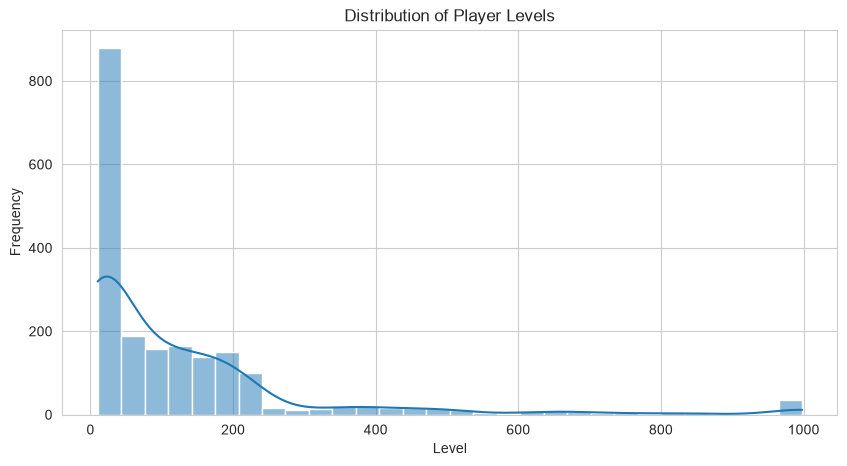

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Level",
    bins=30,
    kde=True
)

plt.title("Distribution of Player Levels")
plt.xlabel("Level")
plt.ylabel("Frequency")

plt.show()

The distribution of player levels is highly right-skewed.

Most players are concentrated at lower progression levels, while a smaller group reaches substantially higher levels, creating a long right tail in the distribution.

This pattern suggests the coexistence of different player profiles, ranging from low-engagement or early-stage players to highly committed users with advanced progression.

Additionally, a small number of extreme values are visible near the upper end of the distribution, which may require further investigation during the outlier analysis stage.

### <font color='green'>**3.1.2 Time Played Distribution**</font>

In this section, we analyze the distribution of time played across all records.

Time played is a key engagement metric that reflects the amount of time players spend interacting with the game and may help distinguish different behavioral profiles.

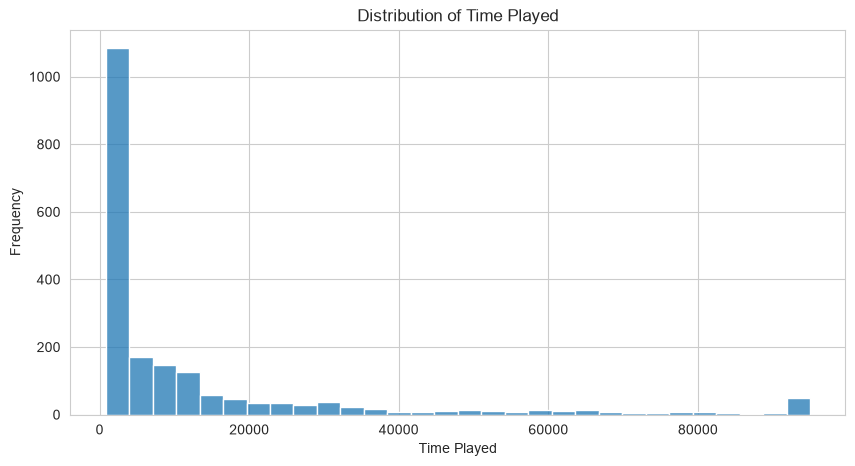

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time Played",
    bins=30,
    kde=False
)

plt.title("Distribution of Time Played")
plt.xlabel("Time Played")
plt.ylabel("Frequency")

plt.show()

The distribution of time played is strongly right-skewed.

Most players accumulate relatively low playtime values, while a smaller group exhibits substantially higher engagement levels, generating a long right tail in the distribution.

This pattern suggests the presence of distinct engagement profiles within the player base, ranging from occasional players to highly active users.

Additionally, several extreme values are visible at the upper end of the distribution, indicating potential outliers that may influence future analyses and segmentation models.

Note that 45.0% of records sit exactly at the minimum value (800), as documented in section 2.4, so the first bar of the histogram mostly reflects this concentration.

### <font color='green'>**3.1.3 Attempts Distribution**</font>

In this section, we examine the distribution of player attempts.

The number of attempts may provide insights into player persistence, gameplay intensity, and overall engagement with the game.

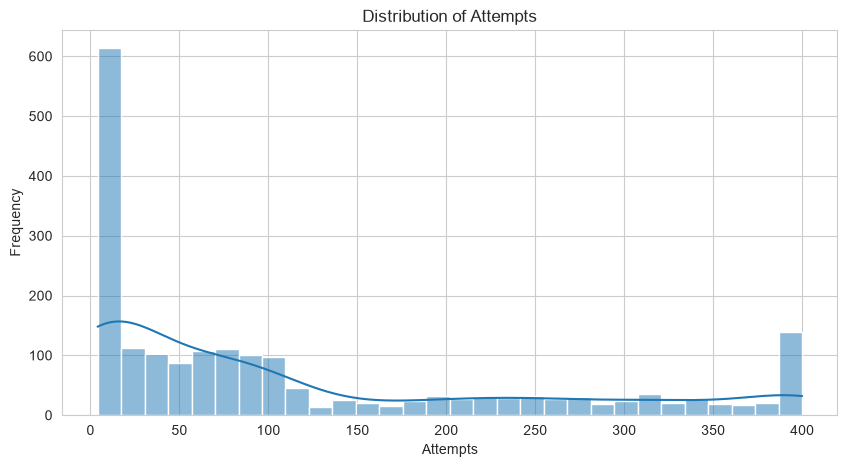

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Attempts",
    bins=30,
    kde=True
)

plt.title("Distribution of Attempts")
plt.xlabel("Attempts")
plt.ylabel("Frequency")

plt.show()

The distribution of attempts is positively skewed, with a large concentration of players at lower attempt counts and a gradual decline as the number of attempts increases.

Unlike the previous variables, this distribution appears more dispersed across the available range, suggesting considerable variation in player behavior and gameplay intensity.

A notable accumulation of observations can be observed near the upper limit of the variable, indicating that some players consistently record very high numbers of attempts.

These findings reinforce the idea that the player base is heterogeneous, with individuals exhibiting substantially different levels of engagement and persistence.

### <font color='green'>**3.1.4 Average Daily Login Distribution**</font>

In this section, we examine the distribution of average daily logins.

Login frequency is an important engagement metric because it reflects how consistently players return to the game and may help differentiate casual users from highly active players.

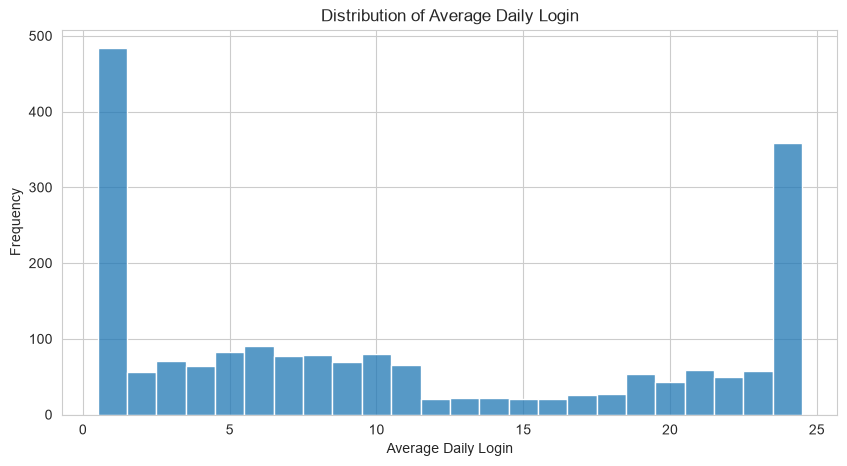

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Avg Daily Login",
    discrete=True,
    kde=False
)

plt.title("Distribution of Average Daily Login")
plt.xlabel("Average Daily Login")
plt.ylabel("Frequency")

plt.show()

The distribution of average daily login is U-shaped: 24.2% of records sit exactly at the minimum (1) and 17.9% exactly at the maximum (24), while the values in between are spread more evenly.

As documented in section 2.4, these two spikes are concentrations at the lower and upper bounds of the variable, not necessarily two natural behavioral groups. The dataset does not allow us to determine whether they reflect real behavior or measurement limits.

This variable may still help separate players with low and high activity in the clustering stage, but its bounds should be taken into account when interpreting the results.

### <font color='green'>**3.1.5 Purchase Amount Distribution**</font>

In this section, we examine the distribution of purchase amounts among players who have made in-game purchases.

Monetization is a key business dimension, and understanding spending behavior may help identify high-value players and potential revenue-driving segments.

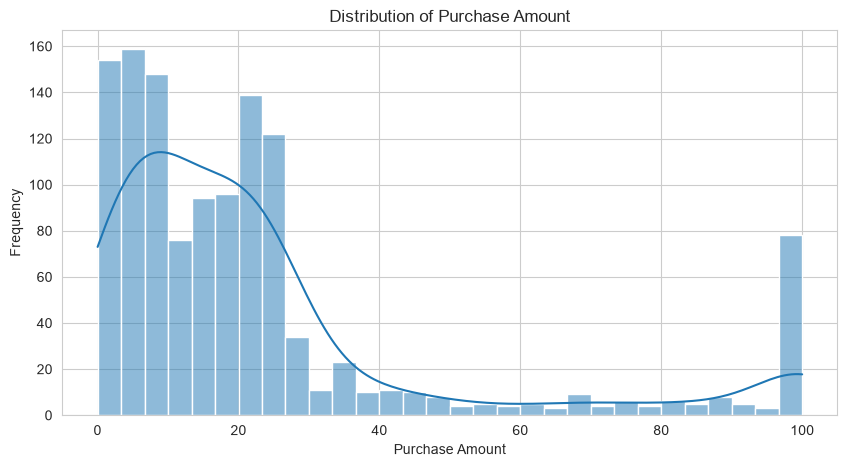

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Purchase Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")

plt.show()

The distribution of purchase amounts is strongly right-skewed, with most transactions concentrated in the lower spending range.

A large proportion of players make relatively small purchases, while a much smaller group spends substantially higher amounts, creating a long right tail in the distribution.

Notably, a concentration of observations is visible near the maximum purchase value, suggesting the presence of a subset of high-spending players. From a business perspective, these users may represent a particularly valuable segment due to their disproportionate contribution to revenue.

Overall, the distribution indicates considerable variability in spending behavior and supports the hypothesis that distinct monetization profiles may exist within the player base.

### <font color='green'>**3.1.6 Guild Chat Messages Distribution**</font>

In this section, we examine the distribution of guild chat messages.

Social interaction is an important component of player engagement, and communication activity may help identify players who are more connected to the game community.

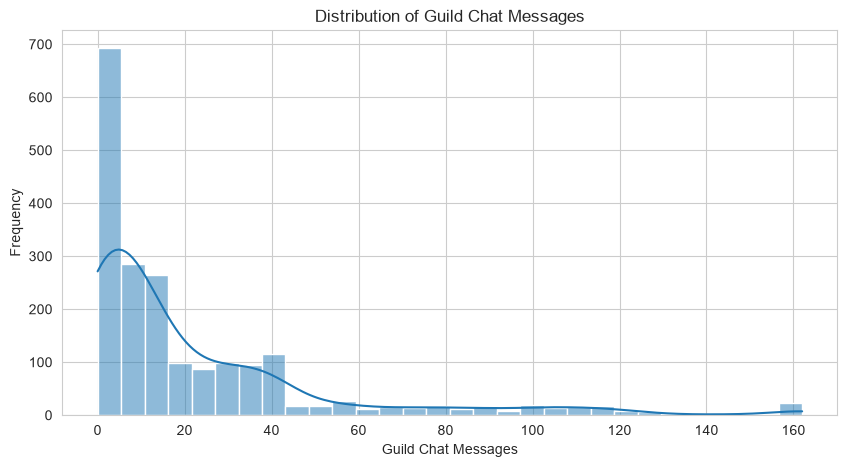

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Guild Chat Messages",
    bins=30,
    kde=True
)

plt.title("Distribution of Guild Chat Messages")
plt.xlabel("Guild Chat Messages")
plt.ylabel("Frequency")

plt.show()

The distribution of guild chat messages is strongly right-skewed, with most players sending relatively few messages while a smaller group exhibits substantially higher levels of social activity.

This pattern suggests that social participation varies considerably across the player base, ranging from minimally engaged users to highly interactive community members.

The long right tail indicates the presence of players who contribute disproportionately to social interactions within the game. These individuals may represent an important segment characterized by strong community engagement.

Overall, the variability observed in this feature reinforces the potential value of social behavior as a dimension for player segmentation.

### <font color='green'>**3.1.7 Distribution Analysis Summary**</font>

The analysis of key numerical variables reveals significant heterogeneity in player behavior across progression, engagement, monetization, and social interaction metrics.

Several variables exhibit strong right-skewed distributions, indicating that while most players remain concentrated at lower activity levels, a smaller subset demonstrates substantially higher engagement, progression, spending, or social participation.

Notably, Avg Daily Login concentrates a large share of records at both of its bounds (1 and 24), as documented in section 2.4.

These findings provide preliminary evidence that the player base is not homogeneous and support the project's central hypothesis that meaningful player segments may exist within the dataset.

## <font color='green'>🟢 **3.2 Outlier Analysis**</font>


In this section, we investigate the presence of potential outliers within the main numerical variables.

Identifying extreme values is important because they may influence statistical summaries, visualizations, and clustering algorithms used later in the project.

At this stage, the objective is not to remove observations, but to understand the variability and distribution of player behaviors across the dataset.

### <font color='green'>**3.2.1 Numerical Variables Overview**</font>

Before analyzing individual variables, we begin with a consolidated view of the main numerical features.

Boxplots provide an efficient way to identify potential outliers, assess distribution spread, and compare variability across different behavioral dimensions.

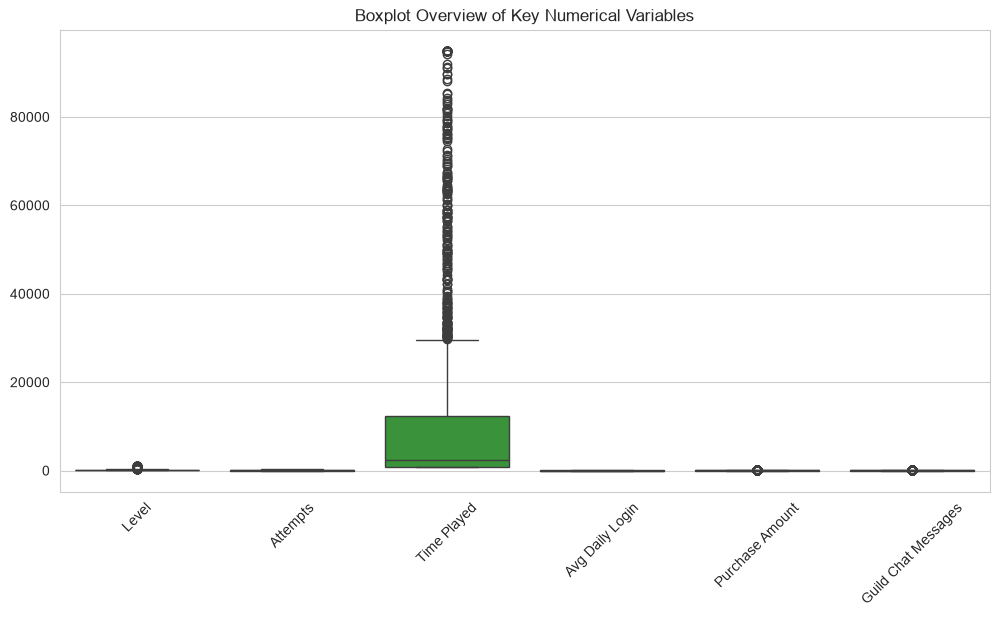

In [21]:
numerical_features = [
    "Level",
    "Attempts",
    "Time Played",
    "Avg Daily Login",
    "Purchase Amount",
    "Guild Chat Messages"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_features])

plt.title("Boxplot Overview of Key Numerical Variables")
plt.xticks(rotation=45)

plt.show()

The consolidated boxplot reveals the presence of potential outliers across several numerical variables, particularly within engagement-related features.

However, the visualization is heavily influenced by the scale of `Time Played`, whose range is substantially larger than that of the other variables. As a result, direct comparisons between variables become more challenging.

Despite this limitation, the plot provides preliminary evidence of considerable variability in player behavior, reinforcing the importance of feature scaling prior to clustering and segmentation tasks.

### <font color='green'>**3.2.2 Outlier Analysis Summary**</font>

The boxplot overview confirms the presence of potential outliers across several numerical variables, particularly within engagement and monetization-related features.

However, these extreme observations appear consistent with the patterns identified during the distribution analysis and may reflect genuine differences in player behavior rather than data quality issues.

Given the nature of the project, these observations should not be treated as erroneous records at this stage. Instead, they represent potentially valuable information that may help distinguish highly engaged, highly social, or high-spending players during the segmentation process.

Therefore, no outlier treatment will be applied during the exploratory phase. Scaling will put the variables on a comparable scale, but it does not remove the influence of extreme values; this is acknowledged as a limitation of K-Means in notebook 4.

## <font color='green'>🟢 **3.3 Correlation Analysis**</font>

In this section, we examine the relationships between key numerical variables.

Understanding how progression, engagement, monetization, and social activity interact can reveal meaningful behavioral patterns and provide valuable insights for both business decision-making and future player segmentation.

By identifying strong and weak relationships between variables, we can better understand the factors that may contribute to different player profiles.

### <font color='green'>**3.3.1 Correlation Matrix**</font>

We begin by analyzing the correlation structure of the main numerical variables.

A correlation matrix provides a high-level view of monotonic relationships between variables and can help identify patterns that may support the project's business hypotheses.

Spearman correlation is used because most variables are strongly skewed.


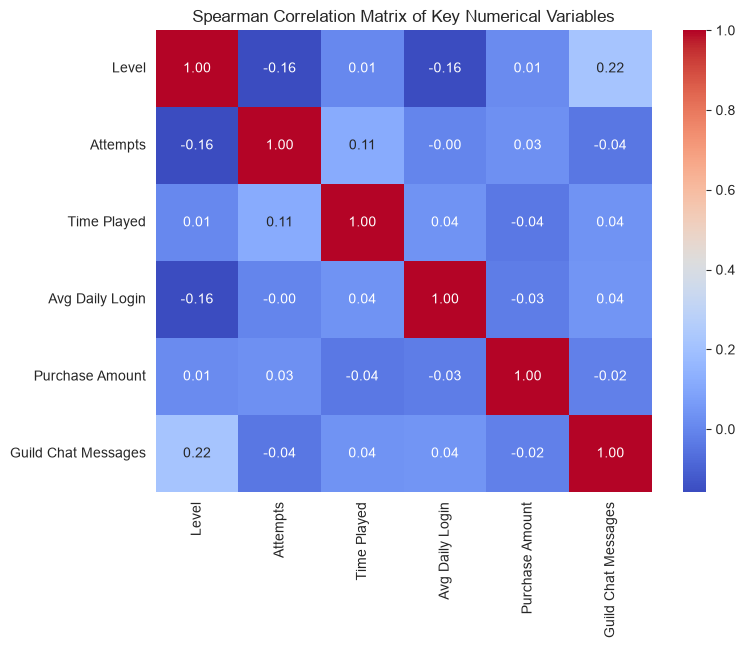

In [22]:
corr_df = df[
   ["Level", "Attempts", "Time Played", "Avg Daily Login",
    "Purchase Amount", "Guild Chat Messages"]
].copy()

# Non-purchases count as zero, as decided in section 2.1.6
corr_df["Purchase Amount"] = corr_df["Purchase Amount"].fillna(0)

correlation_matrix = corr_df.corr(method="spearman")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Spearman Correlation Matrix of Key Numerical Variables")
plt.show()

The correlation matrix reveals generally weak monotonic relationships among the selected numerical variables.

None of the feature pairs exhibit strong positive or negative correlations, suggesting that progression, engagement, monetization, and social activity capture different dimensions of player behavior.

From a segmentation perspective, this finding is valuable because it indicates that the variables provide complementary information rather than measuring the same underlying behavior.

Additionally, the absence of strong correlations reduces concerns about multicollinearity and supports the inclusion of multiple behavioral dimensions in the future clustering analysis.

Overall, these results reinforce the idea that player behavior is complex and cannot be adequately explained by a single metric, further supporting the need for a multi-dimensional segmentation approach.


### <font color='green'>**3.3.2 Correlation Analysis Summary**</font>

The correlation analysis identified only weak relationships among the key numerical variables.

This suggests that player behavior cannot be reduced to a single engagement or progression indicator and instead reflects multiple independent dimensions, including gameplay activity, monetization, and social participation.

These findings support the use of several features in the upcoming segmentation process and highlight the importance of analyzing players from a holistic behavioral perspective.

### <font color='green'>**3.3.3 Initial Hypotheses Check**</font>

The initial hypotheses formulated in notebook 1 (section 1.4) can be partially contrasted with the data before the segmentation stage. Hypotheses 1, 2, and 4 describe pairwise relationships between variables, so they are evaluated here using **Spearman correlation**, which is more suitable than Pearson correlation for the strongly skewed variables of this dataset because it measures whether two variables increase together without assuming a linear relationship.

- **H1:** players with higher engagement are more likely to spend money. We correlate a purchase indicator (1 if the record has a purchase amount, 0 otherwise) with `Time Played`, `Avg Daily Login`, and `Level`.
- **H2:** players with more social activity show higher engagement. We correlate the social variables with `Time Played` and `Avg Daily Login`.
- **H4:** players with more frequent logins reach higher progression. We correlate `Avg Daily Login` with `Level`, `Time Played`, and `Attempts`.

As a reference for interpretation, absolute values below 0.10 are considered negligible, between 0.10 and 0.30 weak, and between 0.30 and 0.50 moderate. Hypothesis 3 (existence of distinct segments) is not evaluated here, since it is addressed by the clustering analysis.

In [23]:
analysis_df = df.copy()
analysis_df["has_purchase"] = df["Purchase Amount"].notna().astype(int)

spearman = analysis_df.corr(method="spearman", numeric_only=True)

hypothesis_pairs = [
    ("H1", "has_purchase", "Time Played"),
    ("H1", "has_purchase", "Avg Daily Login"),
    ("H1", "has_purchase", "Level"),
    ("H2", "Friend Invites Sent", "Time Played"),
    ("H2", "Friend Invites Sent", "Avg Daily Login"),
    ("H2", "Friend Invites Received", "Time Played"),
    ("H2", "Friend Invites Received", "Avg Daily Login"),
    ("H2", "Guild Chat Messages", "Time Played"),
    ("H2", "Guild Chat Messages", "Avg Daily Login"),
    ("H4", "Avg Daily Login", "Level"),
    ("H4", "Avg Daily Login", "Time Played"),
    ("H4", "Avg Daily Login", "Attempts"),
]

hypothesis_check = pd.DataFrame(
    [(h, a, b, spearman.loc[a, b]) for h, a, b in hypothesis_pairs],
    columns=["hypothesis", "variable_a", "variable_b", "spearman"]
).round(2)

hypothesis_check

,hypothesis,variable_a,variable_b,spearman
0,H1,has_purchase,Time Played,-0.05
1,H1,has_purchase,Avg Daily Login,-0.03
2,H1,has_purchase,Level,0.01
3,H2,Friend Invites Sent,Time Played,0.08
4,H2,Friend Invites Sent,Avg Daily Login,0.05
5,H2,Friend Invites Received,Time Played,0.06
6,H2,Friend Invites Received,Avg Daily Login,0.00
7,H2,Guild Chat Messages,Time Played,0.04
8,H2,Guild Chat Messages,Avg Daily Login,0.04
9,H4,Avg Daily Login,Level,-0.16


The results do not support the three hypotheses evaluated:

- **H1 (engagement and spending):** the purchase indicator has negligible correlations with `Time Played` (-0.05), `Avg Daily Login` (-0.03), and `Level` (0.01). In this dataset, more engaged records are not more likely to have made a purchase.
- **H2 (social activity and engagement):** all six correlations are between 0.00 and 0.08, which is negligible. Some of these values may be statistically distinguishable from zero given the sample size, but their magnitude is too small to be practically relevant.
- **H4 (login frequency and progression):** `Avg Daily Login` shows no relationship with `Time Played` (0.04) or `Attempts` (0.00), and a weak **negative** correlation with `Level` (-0.16), which is the opposite direction to the one hypothesized.

Overall, the engagement, social, and monetization variables behave as largely independent dimensions. This is consistent with the weak correlations found in section 3.3.1 and with the idea that player behavior cannot be summarized by a single indicator. It also implies that the engagement composite built in the feature engineering stage averages variables that are only weakly related to each other; this limitation is considered in the later stages.

## <font color='green'>🟢 **3.4 Categorical Variables Analysis**</font>

In this section, we explore the main categorical variables available in the dataset.

While numerical variables provide information about progression, engagement, and monetization, categorical features offer additional context regarding player behavior, preferences, and social interaction patterns.

Understanding these distributions may reveal meaningful player characteristics that are not captured by numerical metrics alone.

### <font color='green'>**3.4.1 Device Type Distribution**</font>

In this section, we examine the distribution of device types used by players.

Understanding player device preferences may help identify the dominant platforms within the player base and provide useful context for future behavioral analysis.

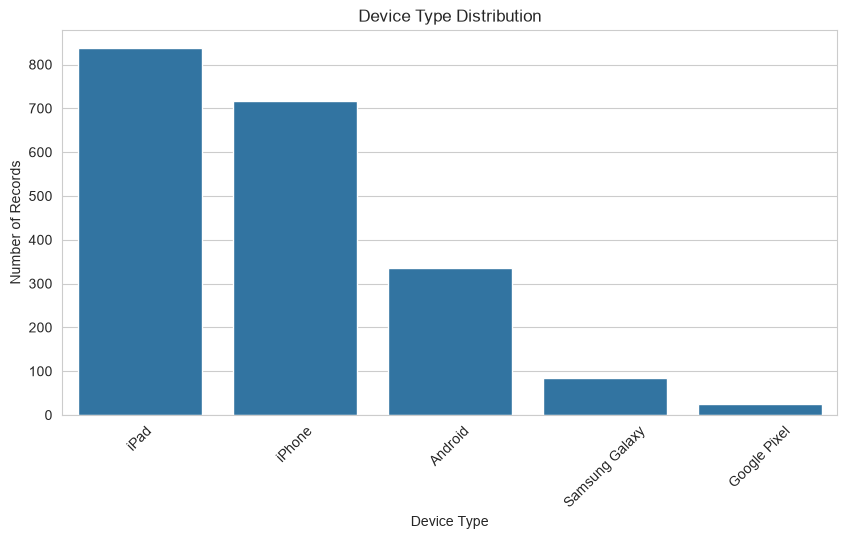

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Device Type",
    order=df["Device Type"].value_counts().index
)

plt.title("Device Type Distribution")
plt.xlabel("Device Type")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

The player base is predominantly composed of users on Apple devices, with **iPad** and **iPhone** representing the largest share of observations in the dataset.

Android devices are also present but at a noticeably lower frequency, while specific devices such as **Samsung Galaxy** and **Google Pixel** account for a relatively small portion of the player population.

From a business perspective, most records come from Apple devices (roughly three out of four).

However, it is important to note that device popularity alone does not imply differences in engagement, monetization, or progression. Additional analysis would be required to determine whether behavioral patterns vary across device types.

### <font color='green'>**3.4.2 Specific Action Usage Distribution**</font>

In this section, we examine the distribution of specific player actions recorded throughout the dataset.

Understanding which actions are most frequently performed may provide additional insights into player preferences, gameplay habits, and engagement patterns.

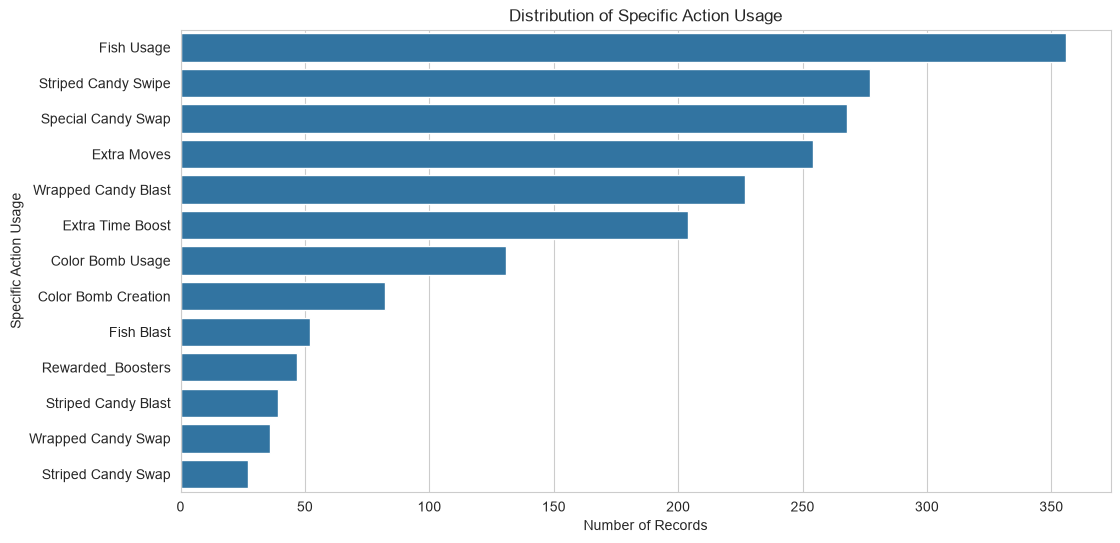

In [25]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Specific Action Usage",
    order=df["Specific Action Usage"].value_counts().index
)

plt.title("Distribution of Specific Action Usage")
plt.xlabel("Number of Records")
plt.ylabel("Specific Action Usage")

plt.show()

The distribution of specific actions is not uniform across the player base.

Several actions, such as **Fish Usage**, **Striped Candy Swipe**, **Special Candy Swap**, and **Extra Moves**, appear considerably more frequently than the remaining categories, suggesting that these mechanics play a more prominent role in player interaction.

In contrast, actions such as **Striped Candy Blast**, **Wrapped Candy Swap**, and **Rewarded_Boosters** are observed much less frequently, indicating lower adoption rates among players.

From a product analytics perspective, this distribution suggests that players may exhibit different gameplay preferences and interaction patterns. These behavioral differences could contribute valuable information during the segmentation process, helping distinguish players based on how they engage with core game mechanics.

### <font color='green'>**3.4.3 Facebook Connection Status**</font>

In this section, we analyze the distribution of Facebook connection status among players.

Social connectivity can be an important indicator of player engagement, community participation, and potential network effects within the game ecosystem.

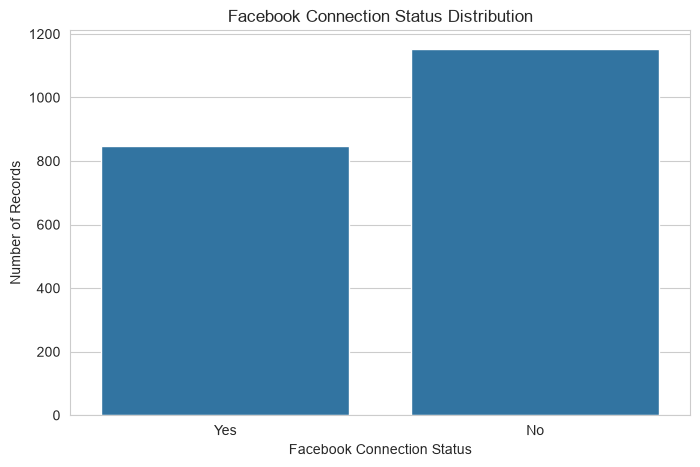

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Facebook Connect Status"
)

plt.title("Facebook Connection Status Distribution")
plt.xlabel("Facebook Connection Status")
plt.ylabel("Number of Records")

plt.show()

In [27]:
df["Facebook Connect Status"].value_counts(normalize=True).mul(100).round(1)

Facebook Connect Status
No     57.7
Yes    42.3
Name: proportion, dtype: float64

A majority of records (**57.7%**) have not connected a Facebook account, while **42.3%** have. The split is moderately balanced: Facebook integration is not a niche feature, since more than four in ten records use it.

This suggests that Facebook connection status may be a meaningful behavioral characteristic, particularly when combined with engagement, social interaction, and monetization metrics.

Further analysis would be required to determine whether connected records exhibit different behavioral patterns compared to those that are not connected.

### <font color='green'>**3.4.4 Social Engagement Through Facebook**</font>

In this section, we analyze the distribution of social engagement levels associated with Facebook activity.

This variable may provide additional insights into how players interact with the game's social ecosystem and could serve as a complementary indicator of player engagement.

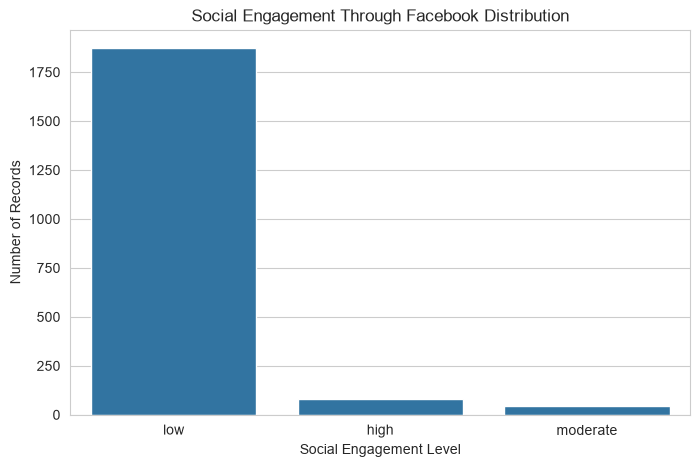

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Social Engagement through Facebook",
    order=df["Social Engagement through Facebook"].value_counts().index
)

plt.title("Social Engagement Through Facebook Distribution")
plt.xlabel("Social Engagement Level")
plt.ylabel("Number of Records")

plt.show()

In [29]:
df["Social Engagement through Facebook"].value_counts(normalize=True).mul(100).round(1)

Social Engagement through Facebook
low         93.6
high         4.0
moderate     2.4
Name: proportion, dtype: float64

The distribution of Facebook social engagement is highly imbalanced: **93.6%** of records are classified as **low**, while only **4.0%** are **high** and **2.4%** are **moderate**.

This indicates that high Facebook-based social engagement is uncommon in the dataset. Even though 42.3% of records have a connected account (section 3.4.3), most connected accounts show low engagement, so connecting an account does not imply an active social use of it.

This variable only captures social engagement through Facebook. Social activity inside the game (friend invites and guild chat) is analyzed separately and is the basis of the `social_score` built in the feature engineering stage.

Because of the strong imbalance, the small group with high engagement (4.0% of records) should be interpreted with caution in later stages, as it may be too small to define a segment on its own.

### <font color='green'>**3.4.5 Categorical Variables Analysis Summary**</font>

The analysis of categorical variables describes how records are distributed across devices, in-game actions, and Facebook-related social features. It does not compare behavior across categories; whether the segments differ in these variables is evaluated in notebook 4, section 5.4.3.

Key findings include:

- Apple devices dominate the dataset, with iPad and iPhone representing the largest share of players.
- Several gameplay actions are substantially more popular than others, suggesting differences in how players interact with core game mechanics.
- Facebook integration is used by a significant portion of the dataset: 42.3% of records have a connected account, while 57.7% remain disconnected.
- Social engagement through Facebook is heavily concentrated in the low category (93.6% of records), indicating limited participation in Facebook-based social features for most records.

Overall, these findings complement the numerical analysis by providing additional behavioral context and highlighting potential characteristics that may contribute to future player segmentation.

## <font color='green'>🟢 **3.5 Exploratory Data Analysis Summary**</font>

The exploratory analysis revealed substantial variation across player progression, engagement, monetization, and social behavior metrics.

Several numerical variables exhibited highly skewed distributions, suggesting the coexistence of players with very different activity levels and gameplay patterns.

Correlation analysis showed generally weak linear relationships between key behavioral metrics, indicating that player behavior is multidimensional and cannot be explained by a single feature alone.

Additionally, the categorical analysis described the distribution of device usage, gameplay actions, and Facebook-based social features.

Taken together, these findings are consistent with a heterogeneous player base. Whether this heterogeneity forms distinct segments is evaluated in the clustering stage.

The next stage of the project will focus on feature engineering and data preparation, transforming the available information into a structured analytical dataset suitable for clustering and segmentation techniques.